# 10 · Cancelled sessions: genuine ones, and cancelling to skip the rescan check (v1.2)

How a SmartShop shop ends: the shopper scans the barcode at the SmartShop till, and that is when a
rescan may be requested. **Once the barcode is scanned the session cannot be cancelled.** Before
it, a shopper can cancel SmartShop and pay at a staffed till instead.

Usually that is ordinary: a flat battery, an app crash, a change of mind. But a shopper with hidden
items can also cancel just before the till, pay at a staffed till for what they put on the belt,
keep what they hid, and never face any chance of a rescan. If a cancellation skips the decision:

- any rescan policy can be side-stepped, and the better it targets, the more it loses, because the
  sessions that slip away are the ones it would have rescanned;
- loss measured from the rescans that were completed misses exactly the sessions most likely to
  hold it.

Two sets of rules are compared, for today's random rescans and the v1.1 policy, at the same
colleague time:

| | Today's rules | Closed rules (v1.2) |
|---|---|---|
| Cancel before the till barcode | Pay at a staffed till; no decision | Treated as an exit: the same decision, scored on the scan log so far |
| Crash or flat battery logged *by the app* | As above | Random floor (2%) only, so a genuine failure is never singled out |
| After the barcode | Cannot cancel; a shopper with hidden items may walk out | Same |

At a staffed till everything on the belt is scanned, so honest mistakes are paid for; only items
deliberately hidden are lost. Shoppers who steal respond to the rescan chance they *effectively*
face, so an open loophole also invites more theft. No published figure exists for how often people
cancel, so the base values are stated assumptions (3% of sessions cancelled genuinely, 40% of them
logged by the app; 30–50% of shoppers with hidden items cancel to skip the check; 10% of those
selected walk out), and six other worlds vary them.

Produced by `python -m smartshop.reporting.cancellations`; this notebook reads its outputs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle

set_style()
t = pd.read_csv('../models/cancellations.csv')
meas = pd.read_csv('../models/cancellations_measurement.csv').set_index('rules')
base = t[t.world.isin(['No cancellations (reference)', 'Cancellations as assumed'])]
cols = ['world', 'arm', 'rules', 'loss_remaining', 'loss vs today (open rules)',
        'hidden_loss_escaping_rescans', 'rescans_skipped_or_walked', 'honest_stops',
        'adaptive_stealing', 'colleague_hours']
base[cols].round(3)

,world,arm,rules,loss_remaining,loss vs today (open rules),hidden_loss_escaping_rescans,rescans_skipped_or_walked,honest_stops,adaptive_stealing,colleague_hours
0,No cancellations (reference),Today,-,41639.170,NaN,NaN,NaN,5428.200,0.663,113.444
1,No cancellations (reference),Policy v1.1,-,33363.607,NaN,NaN,NaN,1911.684,0.708,113.444
2,Cancellations as assumed,Today,open,42503.138,0.000,2086.444,306.608,5240.677,0.772,127.611
3,Cancellations as assumed,Policy v1.1,open,37542.211,-0.117,4207.412,233.198,1900.086,0.755,127.611
4,Cancellations as assumed,Today,closed,41653.709,-0.020,401.580,78.687,5170.086,0.686,127.611
5,Cancellations as assumed,Policy v1.1,closed,34212.134,-0.195,724.299,38.978,1832.361,0.721,127.611


## 1. What the loophole costs, and what closing it recovers

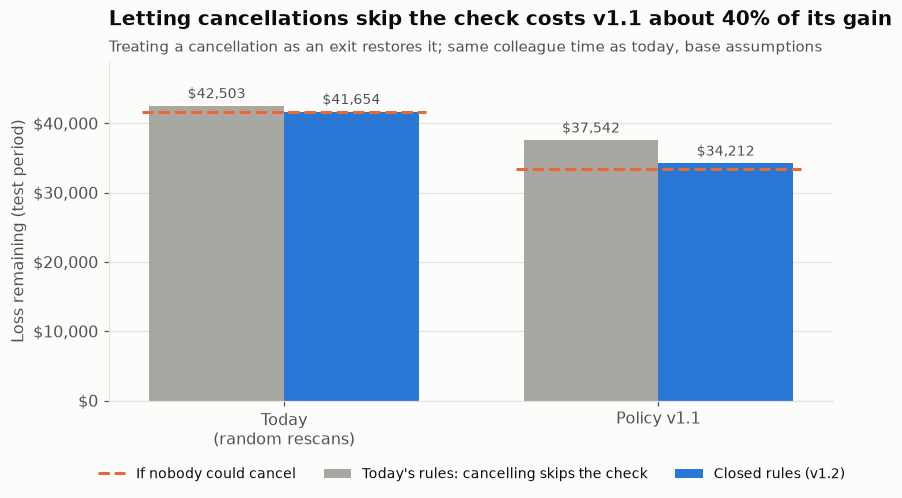

In [2]:
b = t[t.world == 'Cancellations as assumed'].set_index(['arm', 'rules'])
ref = t[t.world == 'No cancellations (reference)'].set_index('arm')
fig, ax = plt.subplots(figsize=(8.5, 4))
labels = ['Today\n(random rescans)', 'Policy v1.1']
x = np.arange(2)
open_ = [b.loc[('Today', 'open'), 'loss_remaining'], b.loc[('Policy v1.1', 'open'), 'loss_remaining']]
closed = [b.loc[('Today', 'closed'), 'loss_remaining'], b.loc[('Policy v1.1', 'closed'), 'loss_remaining']]
b1 = ax.bar(x - 0.18, open_, 0.36, color=GREY, label="Today's rules: cancelling skips the check")
b2 = ax.bar(x + 0.18, closed, 0.36, color=BLUE, label='Closed rules (v1.2)')
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f'${v:,.0f}' for v in bars.datavalues], padding=3, color=TEXT_2, fontsize=9)
for xi, arm in zip(x, ['Today', 'Policy v1.1']):
    ax.hlines(ref.loc[arm, 'loss_remaining'], xi - 0.38, xi + 0.38, color=ORANGE, lw=2, ls='--',
              zorder=3, label='If nobody could cancel' if xi == 0 else None)
ax.set_xticks(x, labels)
ax.set_ylabel('Loss remaining (test period)')
ax.yaxis.set_major_formatter(money())
ax.set_ylim(0, max(open_) * 1.15)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9)
ax.grid(axis='x', visible=False)
ax.set_title('Letting cancellations skip the check costs v1.1 about 40% of its gain')
subtitle(ax, 'Treating a cancellation as an exit restores it; same colleague time as today, base assumptions')
save(fig, '24_cancellation_loophole')
fig

**Reading it.**

- Under today's rules, v1.1 still beats today's random rescans, but its gain shrinks from about
  20% to about 12%. **The loophole costs the risk-based policy more than random rescans**: the
  sessions that cancel to skip the check are the ones v1.1 would most likely have rescanned, so
  the hidden loss that escapes is about twice as large under v1.1 as under today's random rescans.
- Treating a cancellation as an exit brings v1.1 back to about 20% less loss than today, close to
  the no-cancellation reference; what remains is shoppers who walk out after being selected, which
  the store logs.
- An open loophole also invites more theft: adaptive shoppers steal more often when the check can
  be skipped.

## 2. Genuine cancellers

In [3]:
g = t[t.world == 'Cancellations as assumed'].copy()
n_sessions = 47314  # test-period sessions
g['genuine cancellers asked for a rescan'] = g.genuine_cancellers_stopped / g.genuine_cancellations
g['all honest shoppers asked for a rescan'] = g.honest_stops / (n_sessions - g.sessions_with_theft)
g[['arm', 'rules', 'genuine_cancellations', 'genuine cancellers asked for a rescan',
   'all honest shoppers asked for a rescan']].round(3)

,arm,rules,genuine_cancellations,genuine cancellers asked for a rescan,all honest shoppers asked for a rescan
2,Today,open,1350.69,0.000,0.116
3,Policy v1.1,open,1350.24,0.000,0.042
4,Today,closed,1355.40,0.077,0.114
5,Policy v1.1,closed,1352.31,0.033,0.041


Under closed rules a genuine canceller is asked for a rescan **no more often than any honest
shopper who finishes**: a cancellation the app logs as a crash or flat battery gets only the random
floor, and the rest get the same decision as at the exit. Nobody is flagged *for* cancelling, and
mid-shop cancellations are never used as a risk signal. The crash flag must come from the app's own
logs, never from what the shopper says, or it becomes the new loophole.

## 3. Measuring loss when the check can be skipped

In [4]:
meas.round(3)

,bias,error,rescans requested,cancellations,walked out
rules,,,,,
open,-0.336,0.073,2060.233,2431.100,17.3
closed,-0.055,0.113,2079.100,2401.667,27.2


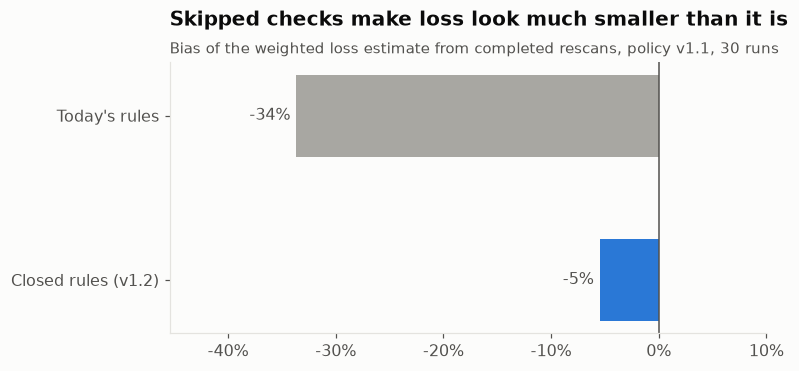

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
vals = [meas.loc['open', 'bias'], meas.loc['closed', 'bias']]
bars = ax.barh(["Today's rules", 'Closed rules (v1.2)'], vals, color=[GREY, BLUE], height=0.5)
ax.bar_label(bars, labels=[f'{v:+.0%}' for v in vals], padding=4, color=TEXT_2)
ax.axvline(0, color=TEXT_2, lw=1)
ax.xaxis.set_major_formatter(pct())
ax.set_xlim(min(vals) * 1.35, 0.1)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_title('Skipped checks make loss look much smaller than it is')
subtitle(ax, 'Bias of the weighted loss estimate from completed rescans, policy v1.1, 30 runs')
save(fig, '25_cancellation_measurement')
fig

The inverse-probability estimate from week 8 assumes every session faced its rescan chance. When a
cancellation skips the decision, the missing sessions are not random: many are shoppers with
something hidden. Under today's rules the estimate misses about a third of the loss; under closed
rules the remaining bias comes only from shoppers who walk out after being selected, and it is
visible: every walk-out is logged, so the store can report it next to the loss estimate.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | If cancelling before the till skips the decision, v1.1's gain falls from about 20% to about 12% less loss than today | The loophole matters more than any modelling choice since week 8 |
| 2 | It costs the risk-based policy more than random rescans: the sessions that slip away are the ones it would most likely have rescanned | Close the loophole before rolling out targeting |
| 3 | Treating a cancellation as an exit (same decision; app-logged crashes get the floor) restores about 20% less loss, and v1.1 stays 16–21% below today in all seven worlds tested | **v1.2 rules** |
| 4 | Genuine cancellers are asked for a rescan no more often than other honest shoppers; nobody is flagged for cancelling | Fair to people with a flat battery |
| 5 | Skipped checks bias the loss estimate by about −34%; under closed rules the bias falls to about −5%, from walk-outs the store can count | Report walk-outs next to the weighted loss estimate |